1.Implement a generator for simulated Voigt signal plus exponential-background events.

2.Verify the generator reproduces its specified distributions and event counts.

3.Generate samples with equal regional resonance centers.

4.Apply the same binned Poisson fitting and shared-center likelihood-ratio test.

5.Measure false-positive rates, estimation bias and confidence-interval coverage.

6.Inject a known 166 MeV difference and measure statistical power for SingleMu-like and DoubleMu-like samples.


# PH3043 — Simulation-Based Closure Tests

## 1. Simulation of a Known Z-Boson Resonance

### Objective

Generate synthetic dimuon invariant-mass distributions
with known resonance centers and investigate whether
the fitting method can recover the injected parameters.

### Scientific motivation

The CERN SingleMu and DoubleMu samples produced different
regional resonance-center estimates.

The cross-dataset difference was not statistically
established at the 95% confidence level.

We now investigate the reliability of the fitting
procedure using synthetic data with known ground truth.

### First experiment: Null regional difference

Both simulated detector regions are assigned the same
resonance center:

$$
m_C = m_F = 90.9\ \mathrm{GeV}
$$

The simulated distribution consists of:

- A Voigt signal profile
- An exponential background
- Poisson fluctuations in event counts

### Important assumptions

The simulation is a statistical model, not a full
simulation of CMS detector physics.

The initial signal fractions and resolution parameters
are illustrative. They are not measured detector
calibration constants.

The hypotheses and evaluation rules are recorded in
hypotheses.md before the main simulation study.


In [5]:
#defining our simulation model

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.special import voigt_profile
from numpy.polynomial.legendre import leggauss

# Fixed seed for reproducibility
rng = np.random.default_rng(3043)

# Mass histogram settings
edges = np.arange(85, 98, 0.5)
centers = (edges[:-1] + edges[1:]) / 2

# Known input resonance center
TRUE_MASS = 90.9  # GeV

# Voigt model parameters
GAMMA = 1.24775  # Lorentzian HWHM, GeV
SIGMA = 1.2       # Illustrative Gaussian smearing, GeV

# Exponential background slope
BACKGROUND_SLOPE = -0.2

# Numerical integration points
nodes, weights = leggauss(24)

half_width = np.diff(edges) / 2
midpoints = (edges[:-1] + edges[1:]) / 2

integration_points = (
    midpoints[:, None]
    + half_width[:, None] * nodes
)

def model_probabilities(
    mass_center,
    sigma=SIGMA,
    gamma=GAMMA,
    slope=BACKGROUND_SLOPE,
    signal_fraction=0.8
):
    # Integrate Voigt signal over each histogram bin
    signal_density = voigt_profile(
        integration_points - mass_center,
        sigma,
        gamma
    )

    signal_bins = half_width * np.sum(
        weights * signal_density,
        axis=1
    )

    # Integrate exponential background
    background_density = np.exp(
        slope * (integration_points - 91)
    )

    background_bins = half_width * np.sum(
        weights * background_density,
        axis=1
    )

    # Normalize within the chosen mass window
    signal_bins /= signal_bins.sum()
    background_bins /= background_bins.sum()

    # Mixture probabilities
    probabilities = (
        signal_fraction * signal_bins
        + (1 - signal_fraction) * background_bins
    )

    return probabilities / probabilities.sum()

print("Number of bins:", len(centers))
print("Injected center:", TRUE_MASS, "GeV")

test_probabilities = model_probabilities(TRUE_MASS)

print("Probability sum:", test_probabilities.sum())

assert np.all(test_probabilities >= 0)
np.testing.assert_allclose(
    test_probabilities.sum(), 1.0
)

print("PASS: Simulation probabilities are valid")


Number of bins: 25
Injected center: 90.9 GeV
Probability sum: 1.0
PASS: Simulation probabilities are valid


In [7]:
#generate simulated events

# Generate synthetic central and forward spectra
# with the SAME true resonance center

SIMULATED_COUNTS = {
    "Central-central": 4073,
    "Forward-containing": 6106
}

def generate_toy(expected_events, true_mass, rng):
    probabilities = model_probabilities(true_mass)

    expected_bin_counts = (
        expected_events * probabilities
    )

    # Poisson fluctuations in each bin
    observed = rng.poisson(expected_bin_counts)

    return observed, expected_bin_counts


toy_samples = {}

for region, n_events in SIMULATED_COUNTS.items():

    observed, expected = generate_toy(
        n_events,
        TRUE_MASS,
        rng
    )

    toy_samples[region] = {
        "observed": observed,
        "expected": expected
    }

    print(
        region,
        "| Expected total:", n_events,
        "| Simulated total:", observed.sum()
    )


Central-central | Expected total: 4073 | Simulated total: 4143
Forward-containing | Expected total: 6106 | Simulated total: 6143


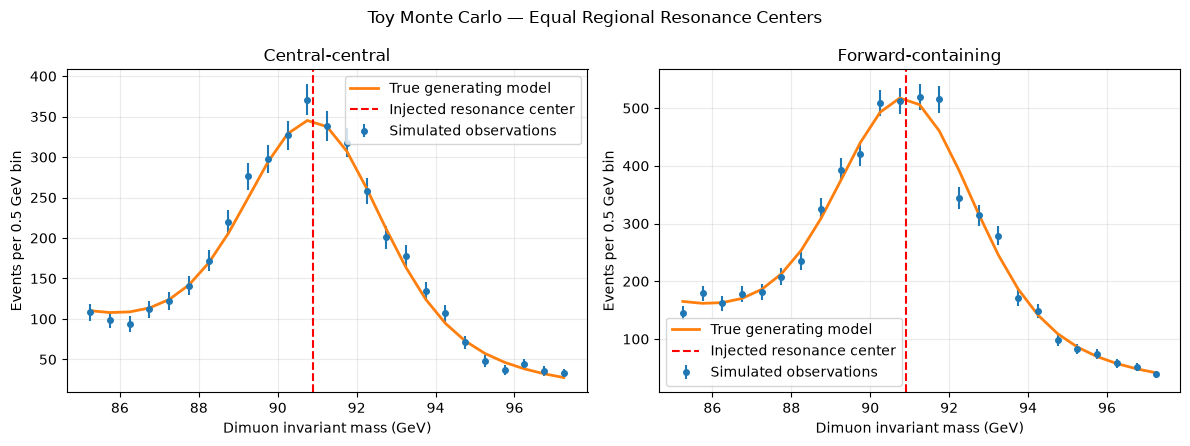

In [9]:
#plot both simulated spectra

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4.5),
    sharex=True
)

for ax, (region, result) in zip(
    axes, toy_samples.items()
):

    observed = result["observed"]
    expected = result["expected"]

    ax.errorbar(
        centers,
        observed,
        yerr=np.sqrt(np.maximum(observed, 1)),
        fmt="o",
        markersize=4,
        label="Simulated observations"
    )

    ax.plot(
        centers,
        expected,
        linewidth=2,
        label="True generating model"
    )

    ax.axvline(
        TRUE_MASS,
        linestyle="--",
        color="red",
        label="Injected resonance center"
    )

    ax.set_title(region)
    ax.set_xlabel("Dimuon invariant mass (GeV)")
    ax.set_ylabel("Events per 0.5 GeV bin")
    ax.grid(alpha=0.25)
    ax.legend()

plt.suptitle(
    "Toy Monte Carlo — Equal Regional Resonance Centers"
)

plt.tight_layout()
plt.show()


In [11]:
#verify the simulation

# Verify input truth and simulated counts

verification = []

for region, result in toy_samples.items():

    observed = result["observed"]
    expected = result["expected"]

    verification.append({
        "Region": region,
        "Injected center (GeV)": TRUE_MASS,
        "Expected events": expected.sum(),
        "Generated events": observed.sum(),
        "Count deviation": (
            observed.sum() - expected.sum()
        )
    })

verification_table = pd.DataFrame(verification)

display(verification_table.round(4))

assert len(toy_samples) == 2

for result in toy_samples.values():
    assert np.all(result["observed"] >= 0)
    assert np.isfinite(result["expected"]).all()

print("PASS: Initial toy simulation generated successfully")


,Region,Injected center (GeV),Expected events,Generated events,Count deviation
0,Central-central,90.9,4073.0,4143,70.0
1,Forward-containing,90.9,6106.0,6143,37.0


PASS: Initial toy simulation generated successfully



## 2. First Closure Test: Recovering the Injected Resonance Center

### Objective

Fit the simulated central and forward mass spectra without
providing the injected resonance-center values to the fitter.

### Method

- Binned Poisson maximum likelihood
- Voigt signal plus exponential background
- Free resonance center and signal fraction
- Fixed gamma, sigma and background slope
- Independent regional fits
- Shared-center versus separate-center likelihood-ratio test

### Expected behavior

The fitted centers should fluctuate around 90.9 GeV.

An apparent nonzero regional difference is possible
even though the injected difference is zero.

One simulation cannot establish the false-positive rate.
Repeated pseudo-experiments will be required.


In [14]:
#fit both simulated regions

from scipy.optimize import minimize
from scipy.special import gammaln
from scipy.stats import chi2
import numpy as np
import pandas as pd

# Negative Poisson log-likelihood
# The total expected count is profiled at the observed total.

def poisson_nll(counts, mass_center, signal_fraction):

    probabilities = model_probabilities(
        mass_center,
        signal_fraction=signal_fraction
    )

    expected = counts.sum() * probabilities

    return np.sum(
        expected
        - counts * np.log(expected)
        + gammaln(counts + 1)
    )


def fit_toy_region(counts):

    def objective(params):
        mass, fraction = params
        return poisson_nll(counts, mass, fraction)

    best = None

    for mass_start in [90.5, 90.9, 91.3]:
        for fraction_start in [0.6, 0.8]:

            result = minimize(
                objective,
                x0=[mass_start, fraction_start],
                method="L-BFGS-B",
                bounds=[
                    (89.0, 93.0),
                    (0.05, 0.99)
                ]
            )

            if result.success and (
                best is None or result.fun < best.fun
            ):
                best = result

    if best is None:
        raise RuntimeError("Toy fit failed")

    return {
        "mass": best.x[0],
        "fraction": best.x[1],
        "nll": best.fun
    }


toy_fits = {}
rows = []

for region, sample in toy_samples.items():

    result = fit_toy_region(sample["observed"])
    toy_fits[region] = result

    rows.append({
        "Region": region,
        "Injected mass (GeV)": TRUE_MASS,
        "Fitted mass (GeV)": result["mass"],
        "Error (MeV)":
            1000 * (result["mass"] - TRUE_MASS),
        "Fitted signal fraction": result["fraction"]
    })

toy_fit_summary = pd.DataFrame(rows)

display(toy_fit_summary.round(5))

observed_difference = 1000 * (
    toy_fits["Central-central"]["mass"]
    - toy_fits["Forward-containing"]["mass"]
)

print(
    f"\nRecovered regional difference: "
    f"{observed_difference:.3f} MeV"
)

print("Injected regional difference: 0.000 MeV")


,Region,Injected mass (GeV),Fitted mass (GeV),Error (MeV),Fitted signal fraction
0,Central-central,90.9,90.86351,-36.48696,0.8255
1,Forward-containing,90.9,90.89386,-6.14265,0.8070



Recovered regional difference: -30.344 MeV
Injected regional difference: 0.000 MeV


In [16]:
#perform shared center hypothesis test 

# Shared-center hypothesis test

central_counts = toy_samples["Central-central"]["observed"]
forward_counts = toy_samples["Forward-containing"]["observed"]

def shared_nll(params):
    mass, f_central, f_forward = params

    return (
        poisson_nll(central_counts, mass, f_central)
        + poisson_nll(forward_counts, mass, f_forward)
    )

shared_solutions = []

for start_mass in [90.5, 90.9, 91.3]:

    result = minimize(
        shared_nll,
        x0=[start_mass, 0.8, 0.8],
        method="L-BFGS-B",
        bounds=[
            (89.0, 93.0),
            (0.05, 0.99),
            (0.05, 0.99)
        ]
    )

    if result.success:
        shared_solutions.append(result)

if not shared_solutions:
    raise RuntimeError("Shared-center fit failed")

best_shared = min(shared_solutions, key=lambda r: r.fun)

nll_shared = best_shared.fun

nll_separate = sum(
    result["nll"] for result in toy_fits.values()
)

q = max(0.0, 2 * (nll_shared - nll_separate))
p_value = chi2.sf(q, df=1)

print("FIRST TOY CLOSURE TEST")
print("-" * 40)

print(f"True center: {TRUE_MASS:.5f} GeV")
print(f"Shared fitted center: {best_shared.x[0]:.5f} GeV")
print(f"Separate-model NLL: {nll_separate:.4f}")
print(f"Shared-model NLL: {nll_shared:.4f}")
print(f"Likelihood-ratio statistic: {q:.4f}")
print(f"Approximate p-value: {p_value:.5f}")

if p_value < 0.05:
    print("This toy rejects the true shared-center hypothesis.")
else:
    print("This toy does not reject the shared-center hypothesis.")


FIRST TOY CLOSURE TEST
----------------------------------------
True center: 90.90000 GeV
Shared fitted center: 90.88147 GeV
Separate-model NLL: 194.7032
Shared-model NLL: 194.8155
Likelihood-ratio statistic: 0.2245
Approximate p-value: 0.63563
This toy does not reject the shared-center hypothesis.



## 3. Repeated Null-Hypothesis Closure Test

### Objective

Measure how often the fitting procedure falsely rejects
the shared-resonance-center hypothesis when the true
regional mass difference is zero.

### Method

Generate 100 independent simulated experiments.

For each experiment:
1. Generate central and forward spectra with equal centers.
2. Fit separate resonance centers.
3. Fit a shared resonance center.
4. Calculate the likelihood-ratio statistic.
5. Record the estimated regional difference and p-value.

### Evaluation

The nominal significance level is alpha = 0.05.

A well-calibrated statistical test should reject the
true null hypothesis approximately 5% of the time,
subject to Monte Carlo sampling uncertainty.

This first study uses the simplified two-parameter
regional fit, not the complete six-parameter real-data fit.


In [19]:
#repeat the null experiment 100 times

from scipy.optimize import minimize
from scipy.stats import chi2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Independent simulation seed
rng_null = np.random.default_rng(3044)

N_TOYS = 100
ALPHA = 0.05

null_results = []

for toy_id in range(N_TOYS):

    # Generate samples under the true null hypothesis
    central_counts, _ = generate_toy(
        4073, TRUE_MASS, rng_null
    )

    forward_counts, _ = generate_toy(
        6106, TRUE_MASS, rng_null
    )

    try:
        # Fit separate centers
        fit_c = fit_toy_region(central_counts)
        fit_f = fit_toy_region(forward_counts)

        nll_separate = fit_c["nll"] + fit_f["nll"]

        # Fit a shared center with separate signal fractions
        def shared_objective(params):
            mass, fc, ff = params

            return (
                poisson_nll(central_counts, mass, fc)
                + poisson_nll(forward_counts, mass, ff)
            )

        shared_candidates = []

        for start_mass in [90.5, 90.9, 91.3]:
            res = minimize(
                shared_objective,
                x0=[
                    start_mass,
                    fit_c["fraction"],
                    fit_f["fraction"]
                ],
                method="L-BFGS-B",
                bounds=[
                    (89.0, 93.0),
                    (0.05, 0.99),
                    (0.05, 0.99)
                ]
            )

            if res.success and np.isfinite(res.fun):
                shared_candidates.append(res)

        if not shared_candidates:
            raise RuntimeError("Shared fit failed")

        shared_best = min(
            shared_candidates,
            key=lambda r: r.fun
        )

        q_raw = 2 * (
            shared_best.fun - nll_separate
        )

        # A negative q beyond rounding indicates a
        # numerical fitting problem, not valid evidence.
        if q_raw < -1e-4:
            raise RuntimeError("Inconsistent likelihood fits")

        q = max(0, q_raw)
        p = chi2.sf(q, df=1)

        null_results.append({
            "Toy": toy_id,
            "Central mass": fit_c["mass"],
            "Forward mass": fit_f["mass"],
            "Difference (MeV)":
                1000 * (fit_c["mass"] - fit_f["mass"]),
            "q": q,
            "p_value": p,
            "Significant": p < ALPHA,
            "Fit_success": True
        })

    except (RuntimeError, ValueError, FloatingPointError):
        null_results.append({
            "Toy": toy_id,
            "Central mass": np.nan,
            "Forward mass": np.nan,
            "Difference (MeV)": np.nan,
            "q": np.nan,
            "p_value": np.nan,
            "Significant": False,
            "Fit_success": False
        })

null_df = pd.DataFrame(null_results)

valid = null_df.loc[null_df["Fit_success"]]

print("NULL SIMULATION SUMMARY")
print("-" * 40)

print("Attempted toys:", N_TOYS)
print("Successful fits:", len(valid))
print("Failed fits:", N_TOYS - len(valid))

if len(valid) > 0:
    false_positives = int(valid["Significant"].sum())
    rate = false_positives / len(valid)

    print("False positives:", false_positives)
    print(f"Observed false-positive rate: {rate:.2%}")
    print("Nominal false-positive rate: 5.00%")

    print(
        "Mean recovered difference (MeV):",
        round(valid["Difference (MeV)"].mean(), 3)
    )

    print(
        "SD of recovered differences (MeV):",
        round(valid["Difference (MeV)"].std(ddof=1), 3)
    )

display(valid.head())


NULL SIMULATION SUMMARY
----------------------------------------
Attempted toys: 100
Successful fits: 100
Failed fits: 0
False positives: 8
Observed false-positive rate: 8.00%
Nominal false-positive rate: 5.00%
Mean recovered difference (MeV): -2.655
SD of recovered differences (MeV): 66.188


,Toy,Central mass,Forward mass,Difference (MeV),q,p_value,Significant,Fit_success
0,0,90.901606,90.910794,-9.188389,0.018808,0.890917,False,True
1,1,90.885601,90.936055,-50.454231,0.601693,0.437933,False,True
2,2,90.928926,90.934954,-6.027589,0.007963,0.928895,False,True
3,3,90.966680,90.899062,67.617993,1.063699,0.302373,False,True
4,4,90.817310,90.900085,-82.774993,1.579886,0.208777,False,True


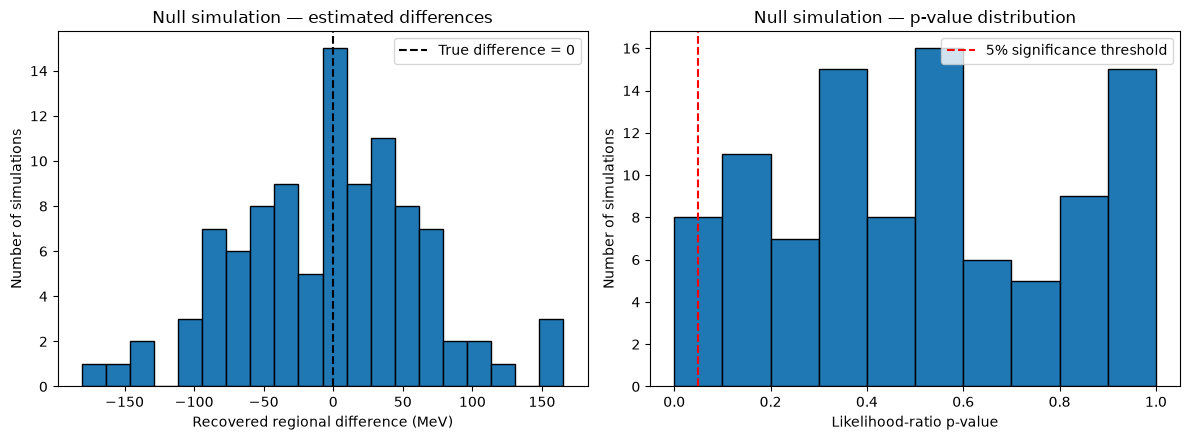

In [20]:
#plot repeated results

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(
    valid["Difference (MeV)"],
    bins=20,
    edgecolor="black"
)

axes[0].axvline(
    0,
    color="black",
    linestyle="--",
    label="True difference = 0"
)

axes[0].set_xlabel("Recovered regional difference (MeV)")
axes[0].set_ylabel("Number of simulations")
axes[0].set_title("Null simulation — estimated differences")
axes[0].legend()

axes[1].hist(
    valid["p_value"],
    bins=np.linspace(0, 1, 11),
    edgecolor="black"
)

axes[1].axvline(
    0.05,
    color="red",
    linestyle="--",
    label="5% significance threshold"
)

axes[1].set_xlabel("Likelihood-ratio p-value")
axes[1].set_ylabel("Number of simulations")
axes[1].set_title("Null simulation — p-value distribution")
axes[1].legend()

plt.tight_layout()
plt.show()



## 4. Statistical Power for a Known Regional Mass Shift

### Objective

Estimate the probability that the simplified fitting
procedure detects a true regional resonance-center
difference of 166 MeV.

### Simulation design

Two independent sample-size configurations are tested:

- SingleMu-like: 4073 central and 6106 forward events
- DoubleMu-like: 1854 central and 2802 forward events

The injected resonance centers are:

- Central: 90.900 GeV
- Forward: 90.734 GeV

Thus the true central-minus-forward difference is +166 MeV.

For each simulated experiment, separate-center and
shared-center models are fitted.

The likelihood-ratio test is evaluated at alpha = 0.05.

### Primary output

Statistical power = fraction of successful simulations
that reject the shared-center hypothesis.

All attempted simulations and optimization failures
will be reported.

### Limitation

This simplified simulation fixes gamma, sigma and
background slope and uses an illustrative signal fraction.

The resulting power is conditional on these assumptions
and is not yet a validation of the full six-parameter
real-data fitting pipeline.


In [24]:
#define simulation experiment

from scipy.optimize import minimize
from scipy.stats import chi2
import numpy as np
import pandas as pd

TRUE_CENTRAL = 90.900
TRUE_FORWARD = TRUE_CENTRAL - 0.166

ALPHA = 0.05
N_POWER_TOYS = 100

rng_power = np.random.default_rng(3045)

sample_sizes = {
    "SingleMu-like": (4073, 6106),
    "DoubleMu-like": (1854, 2802)
}

def fit_shared_center(counts_c, counts_f):

    def objective(parameters):
        mass, fraction_c, fraction_f = parameters

        return (
            poisson_nll(counts_c, mass, fraction_c)
            + poisson_nll(counts_f, mass, fraction_f)
        )

    solutions = []

    for mass_start in [90.5, 90.9, 91.3]:

        result = minimize(
            objective,
            x0=[mass_start, 0.8, 0.8],
            method="L-BFGS-B",
            bounds=[
                (89.0, 93.0),
                (0.05, 0.99),
                (0.05, 0.99)
            ]
        )

        if result.success and np.isfinite(result.fun):
            solutions.append(result)

    if not solutions:
        raise RuntimeError("Shared-center fit failed")

    return min(solutions, key=lambda r: r.fun)


def run_power_experiment(n_c, n_f, n_toys, rng):

    rows = []

    for i in range(n_toys):

        counts_c, _ = generate_toy(
            n_c, TRUE_CENTRAL, rng
        )

        counts_f, _ = generate_toy(
            n_f, TRUE_FORWARD, rng
        )

        try:
            fit_c = fit_toy_region(counts_c)
            fit_f = fit_toy_region(counts_f)

            shared = fit_shared_center(
                counts_c, counts_f
            )

            separate_nll = (
                fit_c["nll"] + fit_f["nll"]
            )

            q_raw = 2 * (
                shared.fun - separate_nll
            )

            if q_raw < -1e-4:
                raise RuntimeError(
                    "Numerically inconsistent fits"
                )

            q = max(q_raw, 0.0)
            p_value = chi2.sf(q, df=1)

            rows.append({
                "Toy": i,
                "Difference (MeV)": 1000 * (
                    fit_c["mass"] - fit_f["mass"]
                ),
                "p_value": p_value,
                "Detected": p_value < ALPHA,
                "Success": True
            })

        except (RuntimeError, ValueError, FloatingPointError):
            rows.append({
                "Toy": i,
                "Difference (MeV)": np.nan,
                "p_value": np.nan,
                "Detected": False,
                "Success": False
            })

    return pd.DataFrame(rows)


power_results = {}

for name, (n_c, n_f) in sample_sizes.items():

    result = run_power_experiment(
        n_c, n_f,
        N_POWER_TOYS,
        rng_power
    )

    power_results[name] = result

print("Power simulations completed.")


Power simulations completed.


In [25]:
#calculate power and confidence interval

from scipy.stats import binomtest

summary = []

for name, result in power_results.items():

    valid = result.loc[result["Success"]]

    successes = len(valid)
    detections = int(valid["Detected"].sum())

    if successes == 0:
        raise RuntimeError(f"No successful toys: {name}")

    estimate = detections / successes

    ci = binomtest(
        detections, successes
    ).proportion_ci(
        confidence_level=0.95,
        method="wilson"
    )

    summary.append({
        "Scenario": name,
        "Attempted": len(result),
        "Successful": successes,
        "Failed": len(result) - successes,
        "Detections": detections,
        "Power (%)": 100 * estimate,
        "95% lower (%)": 100 * ci.low,
        "95% upper (%)": 100 * ci.high,
        "Mean difference (MeV)":
            valid["Difference (MeV)"].mean(),
        "SD difference (MeV)":
            valid["Difference (MeV)"].std(ddof=1)
    })

power_summary = pd.DataFrame(summary)

display(power_summary.round(2))

# Also quantify uncertainty in the previous null result
n_false = int(valid_null["Significant"].sum()) if (
    "valid_null" in globals()
) else int(valid["Detected"].sum()) if False else None

null_valid = null_df.loc[null_df["Fit_success"]]
false_count = int(null_valid["Significant"].sum())

null_ci = binomtest(
    false_count, len(null_valid)
).proportion_ci(
    confidence_level=0.95,
    method="wilson"
)

print(
    f"\nNull false-positive rate: "
    f"{100 * false_count / len(null_valid):.2f}%"
)

print(
    f"95% Wilson interval: "
    f"{100 * null_ci.low:.2f}% to "
    f"{100 * null_ci.high:.2f}%"
)


,Scenario,Attempted,Successful,Failed,Detections,Power (%),95% lower (%),95% upper (%),Mean difference (MeV),SD difference (MeV)
0,SingleMu-like,100,100,0,71,71.0,61.46,78.99,158.31,68.53
1,DoubleMu-like,100,100,0,42,42.0,32.80,51.79,180.11,89.50



Null false-positive rate: 8.00%
95% Wilson interval: 4.11% to 15.00%


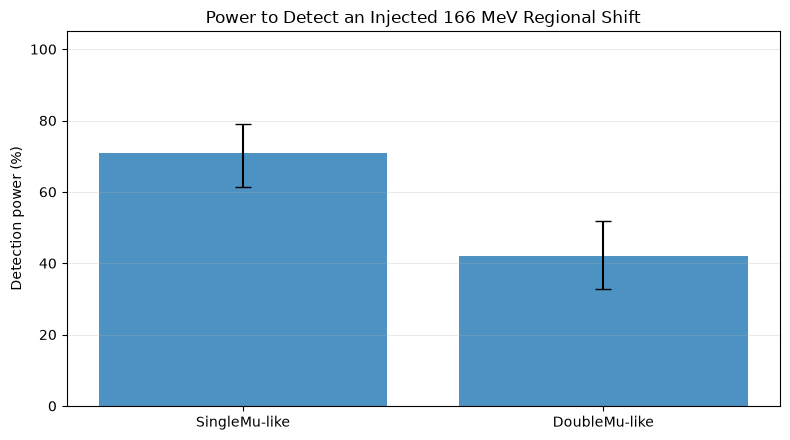

In [26]:
#plotting the estimated statistical power

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.5))

x = np.arange(len(power_summary))

power = power_summary["Power (%)"].to_numpy()
low = power_summary["95% lower (%)"].to_numpy()
high = power_summary["95% upper (%)"].to_numpy()

ax.bar(
    x,
    power,
    yerr=[power - low, high - power],
    capsize=6,
    alpha=0.8
)

ax.set_xticks(x)
ax.set_xticklabels(power_summary["Scenario"])

ax.set_ylim(0, 105)
ax.set_ylabel("Detection power (%)")

ax.set_title(
    "Power to Detect an Injected 166 MeV Regional Shift"
)

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()



## 5. Background-Model Misspecification Test

### Research question

Can differences in background shape cause a fitting
procedure to report an apparent regional resonance-center
difference even when the true centers are identical?

### Simulation design

Both detector categories have an injected resonance
center of 90.900 GeV.

The central background slope is -0.20.
The forward background slope is -0.30.

The fitting procedure incorrectly assumes a fixed
background slope of -0.20 in both regions.

A total of 100 pilot pseudo-experiments are performed.

### Evaluation

Measure:

- Mean estimated regional difference
- Standard deviation of estimated differences
- False-positive rate at alpha = 0.05
- Optimization failures

Compare results against the correctly specified
null simulation.

This experiment assesses model sensitivity, not
physical detector miscalibration.


In [31]:

# Section 5 — Background-model misspecification

from scipy.stats import chi2, binomtest
import numpy as np
import pandas as pd

rng_mismatch = np.random.default_rng(3046)

N_MISMATCH = 100

mismatch_rows = []

for i in range(N_MISMATCH):

    # Same true resonance center, different true backgrounds
    prob_c = model_probabilities(
        TRUE_MASS, slope=-0.20
    )

    prob_f = model_probabilities(
        TRUE_MASS, slope=-0.30
    )

    counts_c = rng_mismatch.poisson(
        4073 * prob_c
    )

    counts_f = rng_mismatch.poisson(
        6106 * prob_f
    )

    try:
        # Both fits assume the DEFAULT slope of -0.20
        fit_c = fit_toy_region(counts_c)
        fit_f = fit_toy_region(counts_f)

        shared = fit_shared_center(
            counts_c, counts_f
        )

        nll_sep = fit_c["nll"] + fit_f["nll"]

        q_raw = 2 * (shared.fun - nll_sep)

        if q_raw < -1e-4:
            raise RuntimeError(
                "Inconsistent likelihood optimization"
            )

        q = max(q_raw, 0.0)
        p = chi2.sf(q, df=1)

        mismatch_rows.append({
            "Toy": i,
            "Difference (MeV)": 1000 * (
                fit_c["mass"] - fit_f["mass"]
            ),
            "p_value": p,
            "False_positive": p < 0.05,
            "Success": True
        })

    except (RuntimeError, ValueError, FloatingPointError):
        mismatch_rows.append({
            "Toy": i,
            "Difference (MeV)": np.nan,
            "p_value": np.nan,
            "False_positive": False,
            "Success": False
        })

mismatch_df = pd.DataFrame(mismatch_rows)

valid_mismatch = mismatch_df[
    mismatch_df["Success"]
]

if len(valid_mismatch) == 0:
    raise RuntimeError("No successful mismatch experiments")

n_false = int(valid_mismatch["False_positive"].sum())
n_valid = len(valid_mismatch)

ci = binomtest(n_false, n_valid).proportion_ci(
    confidence_level=0.95,
    method="wilson"
)

print("BACKGROUND-MISMATCH EXPERIMENT")
print("-" * 40)

print("Attempted:", N_MISMATCH)
print("Successful:", n_valid)
print("Failed:", N_MISMATCH - n_valid)

print(
    "Mean apparent shift (MeV):",
    round(valid_mismatch["Difference (MeV)"].mean(), 3)
)

print(
    "SD of shifts (MeV):",
    round(valid_mismatch["Difference (MeV)"].std(ddof=1), 3)
)

print(f"False-positive rate: {100*n_false/n_valid:.2f}%")
print(
    f"95% Wilson CI: {100*ci.low:.2f}% "
    f"to {100*ci.high:.2f}%"
)


BACKGROUND-MISMATCH EXPERIMENT
----------------------------------------
Attempted: 100
Successful: 100
Failed: 0
Mean apparent shift (MeV): 51.924
SD of shifts (MeV): 62.539
False-positive rate: 11.00%
95% Wilson CI: 6.25% to 18.63%


In [34]:
#compare correct specified models vs misspecified models


# Compare correctly specified vs misspecified background
# Use explicitly named DataFrames to avoid variable conflicts

import pandas as pd

# Recover the original null-simulation results
null_valid = null_df.loc[
    null_df["Fit_success"] == True
].copy()

# Recover the background-mismatch results
mismatch_valid = mismatch_df.loc[
    mismatch_df["Success"] == True
].copy()

comparison = pd.DataFrame([
    {
        "Scenario": "Correct background",
        "Successful toys": len(null_valid),
        "Mean shift (MeV)":
            null_valid["Difference (MeV)"].mean(),
        "SD shift (MeV)":
            null_valid["Difference (MeV)"].std(ddof=1),
        "False-positive rate (%)":
            100 * null_valid["Significant"].mean()
    },
    {
        "Scenario": "Misspecified background",
        "Successful toys": len(mismatch_valid),
        "Mean shift (MeV)":
            mismatch_valid["Difference (MeV)"].mean(),
        "SD shift (MeV)":
            mismatch_valid["Difference (MeV)"].std(ddof=1),
        "False-positive rate (%)":
            100 * mismatch_valid["False_positive"].mean()
    }
])

display(comparison.round(3))


,Scenario,Successful toys,Mean shift (MeV),SD shift (MeV),False-positive rate (%)
0,Correct background,100,-2.655,66.188,8.0
1,Misspecified background,100,51.924,62.539,11.0



## 6. Testing Whether Background Flexibility Removes Bias

### Objective

Determine whether allowing each detector region to have its
own fitted exponential-background slope reduces the apparent
regional mass shift caused by background misspecification.

### Method

Generate synthetic central and forward spectra with identical
true resonance centers of 90.900 GeV.

The injected background slopes differ:
- Central: -0.20
- Forward: -0.30

Compare:

1. Fixed-background model: both slopes fixed at -0.20.
2. Flexible-background model: each slope fitted independently.

The same synthetic datasets are fitted using both methods,
allowing a paired comparison.

### Evaluation

Compare the recovered regional mass differences and their
mean biases across repeated simulations.

If the flexible model reduces the average apparent shift,
this supports the importance of background modeling in
resonance-center estimation.

This remains a simplified statistical closure test.


In [37]:

from scipy.optimize import minimize
from scipy.special import gammaln
import numpy as np
import pandas as pd

# Fit mass, signal fraction and background slope

def poisson_nll_flexible(counts, mass, fraction, slope):

    probabilities = model_probabilities(
        mass_center=mass,
        signal_fraction=fraction,
        slope=slope
    )

    expected = counts.sum() * probabilities

    if np.any(expected <= 0) or not np.all(np.isfinite(expected)):
        return 1e100

    return np.sum(
        expected - counts * np.log(expected)
        + gammaln(counts + 1)
    )


def fit_flexible_region(counts):

    def objective(params):
        mass, fraction, slope = params
        return poisson_nll_flexible(
            counts, mass, fraction, slope
        )

    solutions = []

    for mass_start in [90.7, 91.1]:
        for slope_start in [-0.2, -0.35]:

            result = minimize(
                objective,
                x0=[mass_start, 0.8, slope_start],
                method="L-BFGS-B",
                bounds=[
                    (89.0, 93.0),
                    (0.05, 0.99),
                    (-0.8, 0.2)
                ],
                options={"maxiter": 3000}
            )

            if result.success and np.isfinite(result.fun):
                solutions.append(result)

    if not solutions:
        raise RuntimeError("Flexible fit failed")

    best = min(solutions, key=lambda r: r.fun)

    return {
        "mass": best.x[0],
        "fraction": best.x[1],
        "slope": best.x[2],
        "nll": best.fun
    }


# First test the function on a single simulated sample

rng_test = np.random.default_rng(3047)

test_counts = rng_test.poisson(
    4073 * model_probabilities(
        TRUE_MASS, slope=-0.30
    )
)

test_fit = fit_flexible_region(test_counts)

print("Injected mass:", TRUE_MASS)
print("Recovered mass:", round(test_fit["mass"], 5))
print("Injected slope:", -0.30)
print("Recovered slope:", round(test_fit["slope"], 5))
print("Fit completed successfully")


Injected mass: 90.9
Recovered mass: 90.96732
Injected slope: -0.3
Recovered slope: -0.298
Fit completed successfully


In [39]:
#paired comparision of fixed and flexible background

rng_paired = np.random.default_rng(3048)

N_PAIRED = 30

paired_rows = []

for i in range(N_PAIRED):

    counts_c = rng_paired.poisson(
        4073 * model_probabilities(
            TRUE_MASS, slope=-0.20
        )
    )

    counts_f = rng_paired.poisson(
        6106 * model_probabilities(
            TRUE_MASS, slope=-0.30
        )
    )

    try:
        # Previous fixed-background fitting method
        fixed_c = fit_toy_region(counts_c)
        fixed_f = fit_toy_region(counts_f)

        # New flexible-background fitting method
        flexible_c = fit_flexible_region(counts_c)
        flexible_f = fit_flexible_region(counts_f)

        fixed_shift = 1000 * (
            fixed_c["mass"] - fixed_f["mass"]
        )

        flexible_shift = 1000 * (
            flexible_c["mass"] - flexible_f["mass"]
        )

        paired_rows.append({
            "Toy": i,
            "Fixed shift (MeV)": fixed_shift,
            "Flexible shift (MeV)": flexible_shift,
            "Shift reduction (MeV)":
                fixed_shift - flexible_shift,
            "Recovered central slope": flexible_c["slope"],
            "Recovered forward slope": flexible_f["slope"],
            "Success": True
        })

    except (RuntimeError, ValueError, FloatingPointError):

        paired_rows.append({
            "Toy": i,
            "Fixed shift (MeV)": np.nan,
            "Flexible shift (MeV)": np.nan,
            "Shift reduction (MeV)": np.nan,
            "Recovered central slope": np.nan,
            "Recovered forward slope": np.nan,
            "Success": False
        })


paired_df = pd.DataFrame(paired_rows)
paired_valid = paired_df.loc[paired_df["Success"]]

print("PAIRED BACKGROUND-MODEL COMPARISON")
print("-" * 40)

print("Attempted:", N_PAIRED)
print("Successful:", len(paired_valid))
print("Failed:", N_PAIRED - len(paired_valid))

summary = pd.DataFrame({
    "Model": ["Fixed background", "Flexible background"],
    "Mean apparent shift (MeV)": [
        paired_valid["Fixed shift (MeV)"].mean(),
        paired_valid["Flexible shift (MeV)"].mean()
    ],
    "SD (MeV)": [
        paired_valid["Fixed shift (MeV)"].std(ddof=1),
        paired_valid["Flexible shift (MeV)"].std(ddof=1)
    ]
})

display(summary.round(3))

print(
    "\nMean paired reduction (MeV):",
    round(paired_valid["Shift reduction (MeV)"].mean(), 3)
)

print(
    "Mean recovered central slope:",
    round(paired_valid["Recovered central slope"].mean(), 4)
)

print(
    "Mean recovered forward slope:",
    round(paired_valid["Recovered forward slope"].mean(), 4)
)


PAIRED BACKGROUND-MODEL COMPARISON
----------------------------------------
Attempted: 30
Successful: 30
Failed: 0


,Model,Mean apparent shift (MeV),SD (MeV)
0,Fixed background,15.322,61.259
1,Flexible background,-15.088,59.964



Mean paired reduction (MeV): 30.41
Mean recovered central slope: -0.1995
Mean recovered forward slope: -0.3092



## 7. Paired Statistical Comparison of Background Models

### Objective

Evaluate whether fitting the background slope independently
improves resonance-center estimation compared with fixing
the slope incorrectly.

### Method

The same 30 simulated datasets were analyzed using both
models.

We compare:
- Mean regional center bias
- RMSE relative to the known zero shift
- Paired differences between estimated shifts
- 95% confidence interval for the paired mean difference

### Interpretation

A change in the mean estimate does not necessarily
represent improved accuracy.

RMSE includes both bias and statistical variability.
The paired confidence interval evaluates whether the
models produce systematically different estimates.

The 30 simulations are a pilot study.
``

In [42]:

import numpy as np
import pandas as pd
from scipy.stats import t

# Use only successful paired experiments
paired_valid = paired_df.loc[
    paired_df["Success"]
].copy()

fixed = paired_valid["Fixed shift (MeV)"].to_numpy()
flexible = paired_valid["Flexible shift (MeV)"].to_numpy()

# Since true regional shift = 0 MeV
TRUE_SHIFT_MEV = 0.0

# Paired differences
paired_change = fixed - flexible

n = len(paired_change)

mean_change = paired_change.mean()
se_change = paired_change.std(ddof=1) / np.sqrt(n)

# Approximate 95% paired confidence interval
t_critical = t.ppf(0.975, df=n-1)

ci_lower = mean_change - t_critical * se_change
ci_upper = mean_change + t_critical * se_change

# Accuracy metrics
rmse_fixed = np.sqrt(
    np.mean((fixed - TRUE_SHIFT_MEV)**2)
)

rmse_flexible = np.sqrt(
    np.mean((flexible - TRUE_SHIFT_MEV)**2)
)

summary = pd.DataFrame([
    {
        "Model": "Fixed background",
        "Mean bias (MeV)": fixed.mean(),
        "SD (MeV)": fixed.std(ddof=1),
        "RMSE (MeV)": rmse_fixed
    },
    {
        "Model": "Flexible background",
        "Mean bias (MeV)": flexible.mean(),
        "SD (MeV)": flexible.std(ddof=1),
        "RMSE (MeV)": rmse_flexible
    }
])

display(summary.round(3))

print("\nPAIRED COMPARISON")
print("-" * 40)

print("Number of paired toys:", n)
print(f"Mean paired change: {mean_change:.3f} MeV")
print(f"Standard error: {se_change:.3f} MeV")

print(
    f"Approximate 95% CI: "
    f"[{ci_lower:.3f}, {ci_upper:.3f}] MeV"
)

print(
    f"RMSE change (fixed - flexible): "
    f"{rmse_fixed-rmse_flexible:.3f} MeV"
)

print(
    "\nNote: CI is an approximate Monte Carlo interval "
    "for the mean paired change."
)


,Model,Mean bias (MeV),SD (MeV),RMSE (MeV)
0,Fixed background,15.322,61.259,62.148
1,Flexible background,-15.088,59.964,60.856



PAIRED COMPARISON
----------------------------------------
Number of paired toys: 30
Mean paired change: 30.410 MeV
Standard error: 2.934 MeV
Approximate 95% CI: [24.410, 36.411] MeV
RMSE change (fixed - flexible): 1.292 MeV

Note: CI is an approximate Monte Carlo interval for the mean paired change.


In [44]:

# Compare squared estimation errors for paired toys

fixed_squared_error = fixed**2
flexible_squared_error = flexible**2

error_improvement = (
    fixed_squared_error - flexible_squared_error
)

print("PAIRED ACCURACY CHECK")
print("-" * 35)

print(
    "Toys where flexible model has lower error:",
    np.sum(flexible_squared_error < fixed_squared_error),
    "out of", n
)

print(
    "Mean squared-error improvement:",
    round(error_improvement.mean(), 3),
    "MeV²"
)

print(
    "Fixed model RMSE:",
    round(rmse_fixed, 3), "MeV"
)

print(
    "Flexible model RMSE:",
    round(rmse_flexible, 3), "MeV"
)


PAIRED ACCURACY CHECK
-----------------------------------
Toys where flexible model has lower error: 15 out of 30
Mean squared-error improvement: 158.905 MeV²
Fixed model RMSE: 62.148 MeV
Flexible model RMSE: 60.856 MeV


## 8. Extended Paired Background-Model Comparison

The initial 30-toy study found only a small RMSE advantage
for the flexible-background model.

To evaluate its stability, the analysis is repeated with
200 independent simulated experiments using a new fixed seed.

Both fitting approaches are applied to identical simulated
datasets, preserving the paired comparison.

The primary metrics are:
- RMSE of the fitted regional difference
- Mean estimation bias
- Paired mean difference and uncertainty
- Proportion of experiments with lower absolute error
- Optimization failure rate

The true regional difference remains zero.

In [49]:

# ============================================================
# SECTION 8 — EXTENDED PAIRED BACKGROUND-MODEL COMPARISON
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import t

# 1. Simulation settings
rng_paired_200 = np.random.default_rng(3050)

N_PAIRED = 200
TRUE_MASS = 90.900

# Expected events
N_CENTRAL = 4073
N_FORWARD = 6106

# True background slopes
SLOPE_CENTRAL = -0.20
SLOPE_FORWARD = -0.30

# 2. Generate and fit 200 simulated datasets

paired_rows_200 = []

for i in range(N_PAIRED):

    # Generate both regions with identical true mass
    counts_c = rng_paired_200.poisson(
        N_CENTRAL * model_probabilities(
            TRUE_MASS,
            slope=SLOPE_CENTRAL
        )
    )

    counts_f = rng_paired_200.poisson(
        N_FORWARD * model_probabilities(
            TRUE_MASS,
            slope=SLOPE_FORWARD
        )
    )

    try:
        # Model A: fixed background slope (-0.20)
        fixed_c = fit_toy_region(counts_c)
        fixed_f = fit_toy_region(counts_f)

        # Model B: freely fitted background slopes
        flexible_c = fit_flexible_region(counts_c)
        flexible_f = fit_flexible_region(counts_f)

        # Regional difference: central - forward
        fixed_shift = 1000 * (
            fixed_c["mass"] - fixed_f["mass"]
        )

        flexible_shift = 1000 * (
            flexible_c["mass"] - flexible_f["mass"]
        )

        paired_rows_200.append({
            "Toy": i,
            "Fixed shift (MeV)": fixed_shift,
            "Flexible shift (MeV)": flexible_shift,
            "Paired change (MeV)":
                fixed_shift - flexible_shift,
            "Central slope": flexible_c["slope"],
            "Forward slope": flexible_f["slope"],
            "Success": True
        })

    except (RuntimeError, ValueError, FloatingPointError):

        paired_rows_200.append({
            "Toy": i,
            "Fixed shift (MeV)": np.nan,
            "Flexible shift (MeV)": np.nan,
            "Paired change (MeV)": np.nan,
            "Central slope": np.nan,
            "Forward slope": np.nan,
            "Success": False
        })

# 3. Convert results to DataFrame

paired_200_df = pd.DataFrame(paired_rows_200)

successful_200 = paired_200_df.loc[
    paired_200_df["Success"]
].copy()

print("EXTENDED PAIRED SIMULATION")
print("-" * 45)

print("Attempted:", N_PAIRED)
print("Successful:", len(successful_200))
print("Failed:", N_PAIRED - len(successful_200))

if len(successful_200) < 2:
    raise RuntimeError("Not enough successful simulations")

# 4. Extract fitted differences

fixed = successful_200["Fixed shift (MeV)"].to_numpy()
flexible = successful_200["Flexible shift (MeV)"].to_numpy()

paired_change = fixed - flexible
n = len(paired_change)

# 5. Calculate bias, SD and RMSE

rmse_fixed = np.sqrt(np.mean(fixed**2))
rmse_flexible = np.sqrt(np.mean(flexible**2))

summary_200 = pd.DataFrame([
    {
        "Model": "Fixed background",
        "Mean bias (MeV)": fixed.mean(),
        "SD (MeV)": fixed.std(ddof=1),
        "RMSE (MeV)": rmse_fixed
    },
    {
        "Model": "Flexible background",
        "Mean bias (MeV)": flexible.mean(),
        "SD (MeV)": flexible.std(ddof=1),
        "RMSE (MeV)": rmse_flexible
    }
])

print("\nMODEL ACCURACY")
display(summary_200.round(3))

# 6. Paired confidence interval

mean_change = paired_change.mean()
se_change = paired_change.std(ddof=1) / np.sqrt(n)

t_critical = t.ppf(0.975, df=n-1)

ci_low = mean_change - t_critical * se_change
ci_high = mean_change + t_critical * se_change

print("\nPAIRED MODEL COMPARISON")
print("-" * 45)

print(f"Mean paired change: {mean_change:.3f} MeV")
print(
    f"95% CI for mean paired change: "
    f"[{ci_low:.3f}, {ci_high:.3f}] MeV"
)

# 7. Accuracy comparison

better_flexible = np.sum(np.abs(flexible) < np.abs(fixed))
better_fixed = np.sum(np.abs(fixed) < np.abs(flexible))

print("\nACCURACY CHECK")
print("-" * 45)

print("Flexible model better:", better_flexible, "out of", n)
print("Fixed model better:", better_fixed, "out of", n)

print(
    f"RMSE improvement (fixed - flexible): "
    f"{rmse_fixed - rmse_flexible:.3f} MeV"
)

# 8. Background slope recovery

print("\nBACKGROUND SLOPE RECOVERY")
print("-" * 45)

print("Injected central slope:", SLOPE_CENTRAL)
print(
    "Mean recovered central slope:",
    round(successful_200["Central slope"].mean(), 4)
)

print("Injected forward slope:", SLOPE_FORWARD)
print(
    "Mean recovered forward slope:",
    round(successful_200["Forward slope"].mean(), 4)
)


EXTENDED PAIRED SIMULATION
---------------------------------------------
Attempted: 200
Successful: 200
Failed: 0

MODEL ACCURACY


,Model,Mean bias (MeV),SD (MeV),RMSE (MeV)
0,Fixed background,21.932,65.798,69.201
1,Flexible background,-6.088,68.933,69.029



PAIRED MODEL COMPARISON
---------------------------------------------
Mean paired change: 28.020 MeV
95% CI for mean paired change: [25.567, 30.474] MeV

ACCURACY CHECK
---------------------------------------------
Flexible model better: 103 out of 200
Fixed model better: 97 out of 200
RMSE improvement (fixed - flexible): 0.172 MeV

BACKGROUND SLOPE RECOVERY
---------------------------------------------
Injected central slope: -0.2
Mean recovered central slope: -0.2025
Injected forward slope: -0.3
Mean recovered forward slope: -0.3089


In [50]:
#compare mean square error with uncertanities

# Paired bootstrap for mean squared-error improvement

rng_boot = np.random.default_rng(3051)

squared_error_change = fixed**2 - flexible**2

N_BOOT = 5000

bootstrap_mse_changes = np.empty(N_BOOT)

for b in range(N_BOOT):
    idx = rng_boot.integers(0, n, size=n)

    bootstrap_mse_changes[b] = (
        squared_error_change[idx].mean()
    )

mse_ci = np.percentile(
    bootstrap_mse_changes, [2.5, 97.5]
)

print("PAIRED MSE BOOTSTRAP")
print("-" * 45)

print(
    "Mean MSE improvement:",
    round(squared_error_change.mean(), 3), "MeV²"
)

print(
    "95% bootstrap CI:",
    np.round(mse_ci, 3), "MeV²"
)

if mse_ci[0] > 0:
    print("Evidence of lower MSE for the flexible model.")
elif mse_ci[1] < 0:
    print("Evidence of lower MSE for the fixed model.")
else:
    print(
        "No clearly established MSE difference "
        "at the 95% confidence level."
    )


PAIRED MSE BOOTSTRAP
---------------------------------------------
Mean MSE improvement: 23.761 MeV²
95% bootstrap CI: [-609.082  637.717] MeV²
No clearly established MSE difference at the 95% confidence level.


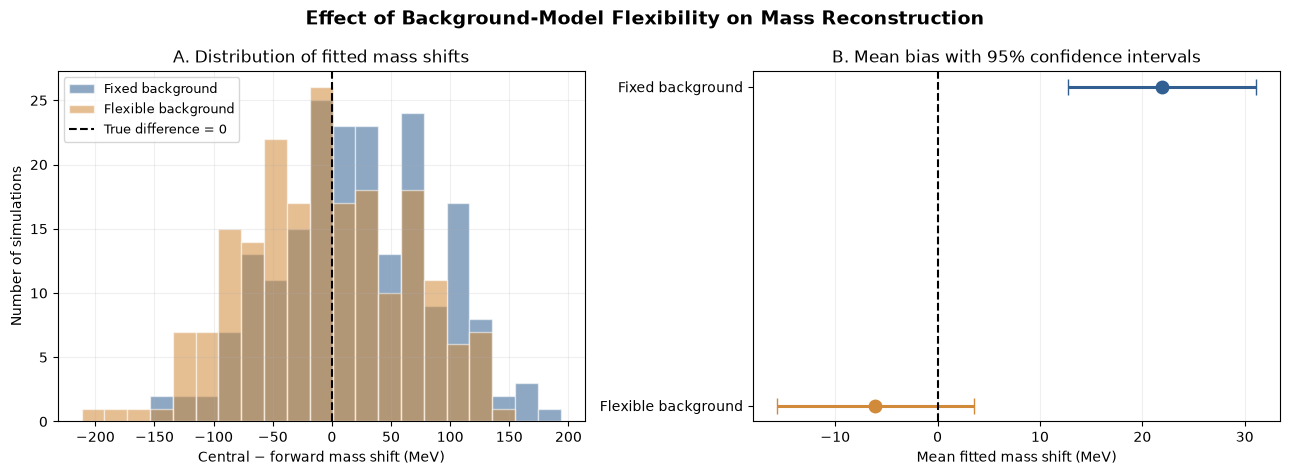

In [53]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t
from pathlib import Path

# Use the completed 200-toy simulation
data = paired_200_df.loc[paired_200_df["Success"]].copy()

fixed = data["Fixed shift (MeV)"].to_numpy()
flexible = data["Flexible shift (MeV)"].to_numpy()

n = len(data)
assert n == 200, f"Expected 200 valid toys, got {n}"

# Save outputs in the project figures folder
fig_dir = Path("../figures")
fig_dir.mkdir(parents=True, exist_ok=True)

# Colors chosen to distinguish both models
colors = ["#315F92", "#D18A39"]
labels = ["Fixed background", "Flexible background"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# PANEL A: Distributions of recovered regional differences
bins = np.linspace(
    min(fixed.min(), flexible.min()) - 10,
    max(fixed.max(), flexible.max()) + 10,
    22
)

axes[0].hist(
    fixed, bins=bins,
    alpha=0.55, color=colors[0],
    edgecolor="white",
    label=labels[0]
)

axes[0].hist(
    flexible, bins=bins,
    alpha=0.55, color=colors[1],
    edgecolor="white",
    label=labels[1]
)

axes[0].axvline(
    0, color="black",
    linestyle="--", linewidth=1.5,
    label="True difference = 0"
)

axes[0].set_title("A. Distribution of fitted mass shifts")
axes[0].set_xlabel("Central − forward mass shift (MeV)")
axes[0].set_ylabel("Number of simulations")
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.2)

# PANEL B: Mean shifts with 95% CI for the mean
means = np.array([fixed.mean(), flexible.mean()])

se = np.array([
    fixed.std(ddof=1) / np.sqrt(n),
    flexible.std(ddof=1) / np.sqrt(n)
])

half_ci = t.ppf(0.975, df=n-1) * se

y_positions = [1, 0]

for i in range(2):
    axes[1].errorbar(
        means[i],
        y_positions[i],
        xerr=half_ci[i],
        fmt="o",
        color=colors[i],
        markersize=9,
        capsize=6,
        linewidth=2.2
    )

axes[1].axvline(
    0, color="black",
    linestyle="--", linewidth=1.5,
    label="True difference = 0"
)

axes[1].set_yticks(y_positions)
axes[1].set_yticklabels(labels)
axes[1].set_xlabel("Mean fitted mass shift (MeV)")
axes[1].set_title("B. Mean bias with 95% confidence intervals")
axes[1].grid(axis="x", alpha=0.2)

fig.suptitle(
    "Effect of Background-Model Flexibility on Mass Reconstruction",
    fontsize=14, fontweight="bold"
)

fig.tight_layout()

fig.savefig(
    fig_dir / "toy_background_model_comparison.png",
    dpi=300, bbox_inches="tight"
)

fig.savefig(
    fig_dir / "toy_background_model_comparison.pdf",
    bbox_inches="tight"
)

plt.show()


In [55]:

from pathlib import Path

results_dir = Path("../results")
results_dir.mkdir(parents=True, exist_ok=True)

paired_200_df.to_csv(
    results_dir / "toy_paired_200_results.csv",
    index=False
)

summary_200.to_csv(
    results_dir / "toy_paired_200_summary.csv",
    index=False
)

print("Saved:")
print("toy_paired_200_results.csv")
print("toy_paired_200_summary.csv")


Saved:
toy_paired_200_results.csv
toy_paired_200_summary.csv



## 9. Detection-Power Map: Sample Size vs Mass Shift

### Research question

How does the statistical power to detect a regional
Z-resonance-center difference depend on the number of
observed events and the size of the true difference?

### Method

We generate synthetic central and forward mass spectra.

The central center is fixed at 90.900 GeV.
The forward center is decreased to inject a known
central-minus-forward mass difference.

Injected differences:
0, 80, 166, and 250 MeV.

Sample sizes:
0.46, 1.0, and 1.5 times the SingleMu regional counts.

For each configuration:

1. Generate independent Poisson-distributed bin counts.
2. Fit separate regional centers.
3. Fit one common regional center.
4. Calculate the likelihood-ratio statistic.
5. Record detection at significance level 0.05.

### Expected outcomes

For a true difference of zero, detection frequency should
be approximately the nominal false-positive rate.

For nonzero differences, detection power is expected to
increase with sample size and effect magnitude.

### Limitations

The simulations use a simplified Voigt-plus-exponential
model with fixed shape and background parameters.

They are not full CMS detector simulations.

Monte Carlo uncertainty and fitting failures must be
reported before interpreting the heatmap.


In [58]:
#run the power map simulation

# ======================================================
# SECTION 9 — STATISTICAL DETECTION-POWER MAP
# ======================================================

import numpy as np
import pandas as pd
from scipy.stats import chi2, binomtest

# Reproducible random seed
rng_map = np.random.default_rng(3052)

# Initial pilot experiment
N_MAP_TOYS = 30

# Injected regional mass differences (MeV)
shifts_mev = [0, 80, 166, 250]

# Sample size multipliers
size_factors = [0.46, 1.0, 1.5]

# Original SingleMu event counts
BASE_CENTRAL = 4073
BASE_FORWARD = 6106

# True central resonance center
MASS_CENTRAL = 90.900

ALPHA_MAP = 0.05

map_rows = []

for factor in size_factors:

    n_c = round(BASE_CENTRAL * factor)
    n_f = round(BASE_FORWARD * factor)

    for shift in shifts_mev:

        mass_forward = (
            MASS_CENTRAL - shift / 1000
        )

        detected_count = 0
        failed_count = 0

        for toy in range(N_MAP_TOYS):

            # Generate synthetic spectra
            counts_c, _ = generate_toy(
                n_c, MASS_CENTRAL, rng_map
            )

            counts_f, _ = generate_toy(
                n_f, mass_forward, rng_map
            )

            try:
                # Separate regional fits
                fit_c = fit_toy_region(counts_c)
                fit_f = fit_toy_region(counts_f)

                # Shared-center null model
                fit_shared = fit_shared_center(
                    counts_c, counts_f
                )

                nll_separate = (
                    fit_c["nll"] + fit_f["nll"]
                )

                q_raw = 2 * (
                    fit_shared.fun - nll_separate
                )

                if q_raw < -1e-4:
                    raise RuntimeError(
                        "Inconsistent likelihood fits"
                    )

                q = max(0, q_raw)

                p_value = chi2.sf(q, df=1)

                if not np.isfinite(p_value):
                    raise RuntimeError(
                        "Nonfinite p-value"
                    )

                if p_value < ALPHA_MAP:
                    detected_count += 1

            except (
                RuntimeError,
                ValueError,
                FloatingPointError
            ):
                failed_count += 1

        successful = N_MAP_TOYS - failed_count

        if successful > 0:

            power = 100 * (
                detected_count / successful
            )

            ci = binomtest(
                detected_count,
                successful
            ).proportion_ci(
                confidence_level=0.95,
                method="wilson"
            )

            ci_low = 100 * ci.low
            ci_high = 100 * ci.high

        else:
            power = np.nan
            ci_low = np.nan
            ci_high = np.nan

        map_rows.append({
            "Size factor": factor,
            "Central events": n_c,
            "Forward events": n_f,
            "Injected shift (MeV)": shift,
            "Attempted": N_MAP_TOYS,
            "Successful": successful,
            "Failed": failed_count,
            "Detections": detected_count,
            "Power (%)": power,
            "CI lower (%)": ci_low,
            "CI upper (%)": ci_high
        })

        print(
            f"Size={factor:.2f}x | "
            f"Shift={shift:3d} MeV | "
            f"Power={power:.1f}% | "
            f"Failed={failed_count}"
        )

map_df = pd.DataFrame(map_rows)

print("\nPOWER MAP SIMULATION COMPLETE")
print("Total attempted:", len(map_df) * N_MAP_TOYS)
print("Total failed:", map_df["Failed"].sum())

display(map_df.round(2))


Size=0.46x | Shift=  0 MeV | Power=10.0% | Failed=0
Size=0.46x | Shift= 80 MeV | Power=10.0% | Failed=0
Size=0.46x | Shift=166 MeV | Power=36.7% | Failed=0
Size=0.46x | Shift=250 MeV | Power=80.0% | Failed=0
Size=1.00x | Shift=  0 MeV | Power=3.3% | Failed=0
Size=1.00x | Shift= 80 MeV | Power=23.3% | Failed=0
Size=1.00x | Shift=166 MeV | Power=63.3% | Failed=0
Size=1.00x | Shift=250 MeV | Power=96.7% | Failed=0
Size=1.50x | Shift=  0 MeV | Power=3.3% | Failed=0
Size=1.50x | Shift= 80 MeV | Power=16.7% | Failed=0
Size=1.50x | Shift=166 MeV | Power=86.7% | Failed=0
Size=1.50x | Shift=250 MeV | Power=100.0% | Failed=0

POWER MAP SIMULATION COMPLETE
Total attempted: 360
Total failed: 0


,Size factor,Central events,Forward events,Injected shift (MeV),Attempted,Successful,Failed,Detections,Power (%),CI lower (%),CI upper (%)
0,0.46,1874,2809,0,30,30,0,3,10.00,3.46,25.62
1,0.46,1874,2809,80,30,30,0,3,10.00,3.46,25.62
2,0.46,1874,2809,166,30,30,0,11,36.67,21.87,54.49
3,0.46,1874,2809,250,30,30,0,24,80.00,62.69,90.49
4,1.00,4073,6106,0,30,30,0,1,3.33,0.59,16.67
5,1.00,4073,6106,80,30,30,0,7,23.33,11.79,40.93
6,1.00,4073,6106,166,30,30,0,19,63.33,45.51,78.13
7,1.00,4073,6106,250,30,30,0,29,96.67,83.33,99.41
8,1.50,6110,9159,0,30,30,0,1,3.33,0.59,16.67
9,1.50,6110,9159,80,30,30,0,5,16.67,7.34,33.56


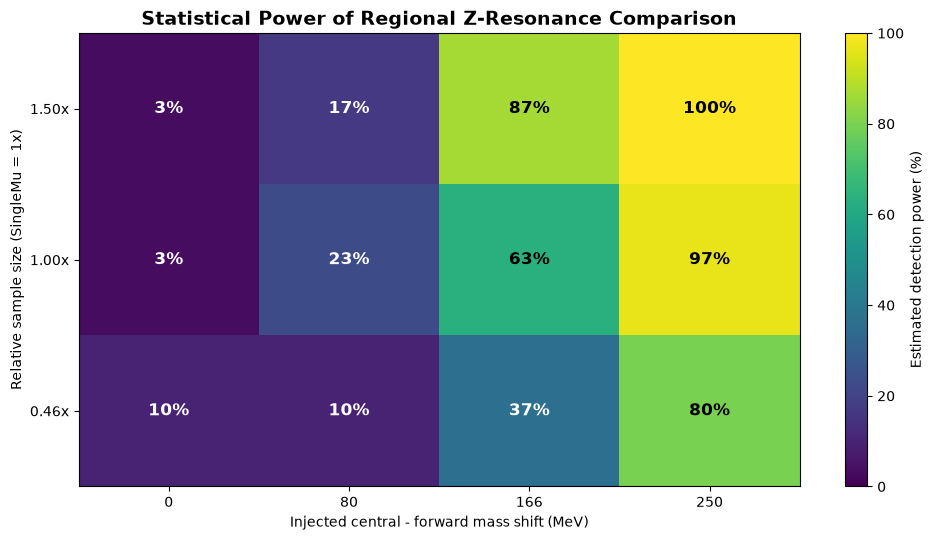

Saved the heatmap and numerical results.


In [59]:
#Draw Actual Heat Map 

# ======================================================
# FINAL DETECTION-POWER HEATMAP
# ======================================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

power_table = map_df.pivot(
    index="Size factor",
    columns="Injected shift (MeV)",
    values="Power (%)"
)

power_table = power_table.sort_index()

fig, ax = plt.subplots(figsize=(10, 5.5))

values = np.ma.masked_invalid(
    power_table.to_numpy()
)

im = ax.imshow(
    values,
    cmap="viridis",
    vmin=0,
    vmax=100,
    aspect="auto",
    origin="lower"
)

# Axis labels
ax.set_xticks(
    np.arange(len(power_table.columns))
)

ax.set_xticklabels(
    power_table.columns.astype(int)
)

ax.set_yticks(
    np.arange(len(power_table.index))
)

ax.set_yticklabels([
    f"{x:.2f}x" for x in power_table.index
])

ax.set_xlabel(
    "Injected central - forward mass shift (MeV)"
)

ax.set_ylabel(
    "Relative sample size (SingleMu = 1x)"
)

ax.set_title(
    "Statistical Power of Regional Z-Resonance Comparison",
    fontsize=14,
    fontweight="bold"
)

# Annotate measured detection rates
for i in range(len(power_table.index)):
    for j in range(len(power_table.columns)):

        value = values[i, j]

        if not np.ma.is_masked(value):
            text_color = (
                "white" if value < 55 else "black"
            )

            ax.text(
                j, i,
                f"{value:.0f}%",
                ha="center",
                va="center",
                fontsize=12,
                fontweight="bold",
                color=text_color
            )

# Legend
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Estimated detection power (%)")

fig.tight_layout()

# Save files
output_dir = Path("../figures")
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "statistical_power_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    output_dir / "statistical_power_heatmap.pdf",
    bbox_inches="tight"
)

plt.show()

# Save statistical results
results_dir = Path("../results")
results_dir.mkdir(parents=True, exist_ok=True)

map_df.to_csv(
    results_dir / "statistical_power_map_results.csv",
    index=False
)

print("Saved the heatmap and numerical results.")
